In [1]:
!pip install netCDF4

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 23.0 -> 26.0.1
[notice] To update, run: python3 -m pip install --upgrade pip


In [ ]:
import numpy as np
import pandas as pd

print("OK")

In [3]:
from netCDF4 import Dataset

# Specify the path to your .nc file
file_path = 'PROJECT/dset_allspec_150_chunks_clean.nc'

# Open the .nc file in read mode
dataset = Dataset(file_path, mode='r')

# Print basic information about the dataset
print(dataset)

# List all variables in the dataset
print("\nVariables in the dataset:")
print(dataset.variables.keys())

# Access a specific variable (replace 'variable_name' with the actual variable name)
variable_name = list(dataset.variables.keys())[0]  # Example: get the first variable
variable_data = dataset.variables[variable_name]

# Print variable details
print(f"\nDetails of the variable '{variable_name}':")
print(variable_data)

# Access data from the variable (e.g., first 5 data points)
data = variable_data[:5]  # Adjust indexing based on data structure
print(f"\nFirst 5 data points of '{variable_name}':")
print(data)

# Close the dataset when done
dataset.close()


<class 'netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    dimensions(sizes): time(2048), traces(70637), comp(3), side(128)
    variables(dimensions): float32 chunk(traces, comp, time), int64 class(traces), float32 distance(traces), int64 seis(traces), int64 image(traces, side, side, comp)
    groups: class_dict

Variables in the dataset:
dict_keys(['chunk', 'class', 'distance', 'seis', 'image'])

Details of the variable 'chunk':
<class 'netCDF4.Variable'>
float32 chunk(traces, comp, time)
unlimited dimensions: 
current shape = (70637, 3, 2048)
filling on, default _FillValue of 9.969209968386869e+36 used

First 5 data points of 'chunk':
[[[-1.62505986e-09  2.56003507e-09 -2.65518690e-10 ... -3.76963044e-12
   -1.31978692e-10 -5.88313842e-11]
  [-1.38451761e-09  2.78957835e-09 -2.56962562e-10 ...  3.24218395e-11
   -2.44652631e-10 -5.94519017e-11]
  [-1.30287237e-09  2.86068746e-09 -2.69089112e-10 ... -2.17682289e-10
   -1.56658486e-12  1.13556005e-10]]

 [[-1.4662

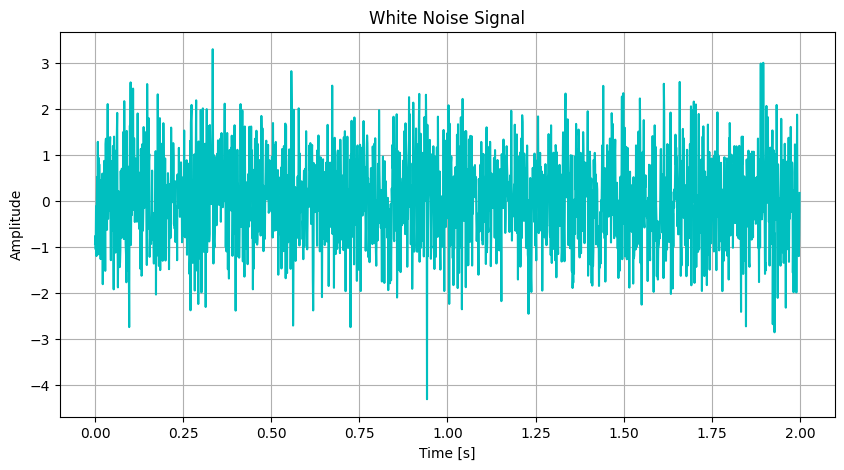

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Set the parameters for the noise signal
duration = 2  # in seconds
sampling_rate = 1000  # samples per second
t = np.linspace(0, duration, duration * sampling_rate, endpoint=False)

# Generate white noise signal
noise_signal = np.random.normal(0, 1, t.shape)

# Plot the noise signal
plt.figure(figsize=(10, 5))
plt.plot(t, noise_signal, color='c')
plt.title("White Noise Signal")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


In [5]:
!pip install scipy

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 23.0 -> 26.0.1
[notice] To update, run: python3 -m pip install --upgrade pip


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Function to check visibility between two points
def visibility_criterion(xi, yi, xj, yj, xk, yk):
    return yk < yi + (yj - yi) * (xk - xi) / (xj - xi)

# Create the visibility graph
def visibility_graph(signal):
    n = len(signal)
    G = nx.Graph()
    
    for i in range(n):
        G.add_node(i)
        for j in range(i+1, n):
            visible = True
            for k in range(i+1, j):
                if not visibility_criterion(i, signal[i], j, signal[j], k, signal[k]):
                    visible = False
                    break
            if visible:
                G.add_edge(i, j)
    return G

# Set the parameters for the noise signal
duration = 2  # in seconds
sampling_rate = 1000  # samples per second
t = np.linspace(0, duration, duration * sampling_rate, endpoint=False)

# Generate white noise signal
noise_signal = np.random.normal(0, 1, t.shape)

# Generate the visibility graph
VG = visibility_graph(noise_signal)

# Plot the visibility graph
plt.figure(figsize=(8, 8))
pos = nx.spring_layout(VG)
nx.draw(VG, pos, node_size=10, node_color='c', edge_color='gray')
plt.title("Visibility Graph of the Noise Signal")
plt.show()


TypeError: '_AxesStack' object is not callable

<Figure size 800x800 with 0 Axes>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Visibility graph function
def visibility_graph(time_series):
    n = len(time_series)
    G = nx.Graph()
    G.add_nodes_from(range(n))
    
    for i in range(n - 1):
        for j in range(i + 1, n):
            visible = True
            for k in range(i + 1, j):
                if time_series[k] >= time_series[i] + (time_series[j] - time_series[i]) * (k - i) / (j - i):
                    visible = False
                    break
            if visible:
                G.add_edge(i, j)
    
    return G

# Set the parameters for the noise signal
duration = 2  # in seconds
sampling_rate = 1000  # samples per second
t = np.linspace(0, duration, duration * sampling_rate, endpoint=False)

# Generate white noise signal
noise_signal = np.random.normal(0, 1, t.shape)

# Construct the visibility graph
G = visibility_graph(noise_signal)

# Visualize the visibility graph
plt.figure(figsize=(12, 8))
nx.draw(G, node_size=10, edge_color='c', node_color='blue', with_labels=False)
plt.title("Visibility Graph of Noise Signal")
plt.show()


In [ ]:
!wget "https://www.dropbox.com/sh/p1swf94hs2pa47g/AAAXce5SfgWKizq7rpTM7wxna/dset_allspec_150?dl=1" -O dset_allspec_150.zip


In [ ]:
# variables in dset_allspec_150_chunks_clean.nc
import netCDF4 as nc
dataset = nc.Dataset(r"/jupyter/aswin.vs/Wildlife_Classification/dset_allspec_150/dset_allspec_150_chunks_clean.nc", "r")

print("Veriables:", dataset.variables.keys())

for var in dataset.variables:
    print(f"Variable: {var}, shape:{dataset.variables[var].shape} , Data Type:{dataset.variables[var].dtype}")

dataset.close()

In [ ]:
!pip install dropbox

In [ ]:
# Code to read the nc file

import os
import sys
import numpy as np
import pandas as pd
import netCDF4 as nc
import time



long_dset = nc.Dataset(r"/jupyter/aswin.vs/Wildlife_Classification/dset_allspec_150/dset_allspec_150_chunks_clean.nc", "r")

# inds_dist = np.where(long_dset["distance"][:]<20)[0]
# new_len = len(inds_dist)
    
print(long_dset)

In [ ]:
import matplotlib.pyplot as plt
for i_chunk, chunk in enumerate(long_dset["chunk"]):
    # if long_dset["distance"][i_chunk] < 20.0:
    if  long_dset["class"][i_chunk] == 4:
        print(i_chunk," And ", len(chunk[0]),long_dset["class"][i_chunk], long_dset["distance"][i_chunk], long_dset["seis"][i_chunk])
        A = long_dset["image"][i_chunk,:,:,:]
        plt.imshow(A)
        break
    
    # plt.plot(np.arange(2048), chunk[2], color='c')
    # break

In [ ]:
print(long_dset)

In [ ]:
i_chunk  = 457
print(i_chunk," And ", len(chunk[0]),long_dset["class"][i_chunk], long_dset["distance"][i_chunk], long_dset["seis"][i_chunk])
A = long_dset["image"][i_chunk,:,:,:]
# plt.imshow(A)
plt.plot(long_dset["chunk"][i_chunk,0,:])

In [ ]:
type(long_dset)

In [ ]:
plt.plot(chunk[0])

In [ ]:
import matplotlib.pyplot as plt
i_chunk=70636
# for i_chunk, chunk in enumerate(long_dset["chunk"]):
    # if long_dset["distance"][i_chunk] < 20.0:
print(i_chunk," And ",long_dset["class"][i_chunk], long_dset["distance"][i_chunk], long_dset["seis"][i_chunk])
A = long_dset["image"][i_chunk,:,:,:]
plt.imshow(A)
    

In [ ]:
chunk=long_dset["chunk"][i_chunk,1]
plt.plot(chunk)

In [ ]:
#go through data select only class 1 distance < 60m

The output you've provided describes a NetCDF file structure, which is often used for storing multidimensional scientific data. Here’s a breakdown of the components:

### Root Group
- **Root Group**: This is the main container for your data, using the NetCDF4 format based on HDF5.

### Dimensions
- **time(2048)**: This dimension has 2048 elements, likely representing time steps in your dataset.
- **traces(70637)**: This dimension has 70,637 elements, possibly representing individual data traces or measurements.
- **comp(3)**: This dimension indicates there are 3 components per trace, which might refer to different channels or features.
- **side(128)**: This dimension has 128 elements, possibly indicating a spatial dimension (like width or height) in a square grid.

### Variables
- **chunk(traces, comp, time)**: A 3D array of floats that holds data for each trace, component, and time step. This is likely the primary data variable.
- **class(traces)**: An array of integers that may represent class labels or categories assigned to each trace.
- **distance(traces)**: An array of floats that could represent a distance measurement associated with each trace.
- **seis(traces)**: An array of integers, possibly representing seismic data or identifiers for each trace.
- **image(traces, side, side, comp)**: A 4D array that stores image data for each trace, where each image has dimensions defined by `side` and contains multiple components.

### Groups
- **class_dict**: This likely indicates a group containing additional metadata or mappings, such as a dictionary that defines what each class label represents.

This structure allows for efficient storage and retrieval of complex datasets, commonly used in fields like geophysics, remote sensing, or environmental science. If you have specific questions or need further details, feel free to ask!

In [ ]:
selected_indices = np.where((long_dset['class'][:] == 2) & (long_dset['distance'][:] < 60))[0]
selected_data = long_dset['chunk'][selected_indices]


In [ ]:
for i in selected_indices:
    A = long_dset["image"][i, :, :, :]  # Extract image data
    plt.imshow(A)
    plt.show()


In [ ]:
!pip install sklearn

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
normalized_chunk = scaler.fit_transform(long_dset['chunk'][:])


In [ ]:



### 1. **Preprocessing & Feature Extraction** (optional: customize based on your data)

# import numpy as np
# from sklearn.preprocessing import StandardScaler


# # Assuming long_dset['chunk'] contains the seismic data (shape: [traces, comp, time])
# seismic_data = long_dset['chunk'][:]


# # Normalize the data across all traces (optional: depending on your data's scale)
# scaler = StandardScaler()
# normalized_data = scaler.fit_transform(seismic_data.reshape(-1, seismic_data.shape[-1])).reshape(seismic_data.shape)


# # Example: You can extract features (mean, std, etc.)
# def extract_features(signal):
#     mean = np.mean(signal)
#     std = np.std(signal)
#     max_val = np.max(signal)
#     min_val = np.min(signal)
#     return np.array([mean, std, max_val, min_val])


# # Apply feature extraction to all traces (example using the first component)
# features = np.array([extract_features(signal[0]) for signal in normalized_data])


# # Filtering: Select class 1 with distance < 60m
# selected_indices = np.where((long_dset['class'][:] == 1) & (long_dset['distance'][:] < 60))[0]
# selected_data = normalized_data[selected_indices]
# selected_features = features[selected_indices]
# ```
# selected_indices = np.where((long_dset['class'][:] == 2) & (long_dset['distance'][:] < 60))[0]
selected_data = long_dset['chunk'][25729]
VG = visibility_graph(selected_data[0])

# Plot the visibility graph
plt.figure(figsize=(8, 8))
pos = nx.spring_layout(VG)
nx.draw(VG, pos, node_size=10, node_color='c', edge_color='gray')
plt.title("Visibility Graph of the Noise Signal")
plt.show()


# ### 2. **Graph Construction** (Using Visibility Graph)

# import networkx as nx


# # Function to create a visibility graph from a seismic signal
# def create_visibility_graph(signal):
#     n = len(signal)
#     G = nx.Graph()
#     for i in range(n):
#         G.add_node(i, value=signal[i])
#         for j in range(i + 1, n):
#             visible = True
#             for k in range(i + 1, j):
#                 if signal[k] >= signal[i] + (signal[j] - signal[i]) * (k - i) / (j - i):
#                     visible = False
#                     break
#             if visible:
#                 G.add_edge(i, j)
#     return G


# # Create visibility graphs for selected data
# # VG = [create_visibility_graph(signal[0]) for signal in selected_data]  # Example with first component
# VG=create_visibility_graph(selected_data[0])

# plt.figure(figsize=(8, 8))
# pos = nx.spring_layout(VG[0])
# nx.draw(VG[0], pos, node_size=10, node_color='c', edge_color='gray')
# plt.title("Visibility Graph of the Noise Signal")
# plt.show()
# # Extract edge indices and node features for PyTorch Geometric
# import torch
# from torch_geometric.data import Data


# def graph_to_data(graph):
#     edge_index = torch.tensor(list(graph.edges), dtype=torch.long).t().contiguous()  # Transpose to get [2, E]
#     node_features = torch.tensor([node[1]['value'] for node in graph.nodes(data=True)], dtype=torch.float).view(-1, 1)  # Feature per node
#     return Data(x=node_features, edge_index=edge_index)


# # Convert graphs to Data objects
# data_list = [graph_to_data(G) for G in graphs]
# ```


# ### 3. **Graph Neural Network (GNN) Model**
# ```python
# import torch
# import torch.nn as nn
# from torch_geometric.nn import GCNConv


# # Define the GNN model
# class GNNModel(nn.Module):
#     def __init__(self, in_channels, out_channels):
#         super(GNNModel, self).__init__()
#         self.conv1 = GCNConv(in_channels, 64)
#         self.conv2 = GCNConv(64, out_channels)


#     def forward(self, data):
#         x, edge_index = data.x, data.edge_index  # Node features and edges
#         x = self.conv1(x, edge_index)
#         x = torch.relu(x)
#         x = self.conv2(x, edge_index)
#         return x


# # Initialize the model, loss function, and optimizer
# model = GNNModel(in_channels=1, out_channels=len(np.unique(long_dset['class'][:])))  # Assuming the number of classes matches the output channels
# loss_fn = nn.CrossEntropyLoss()  # Classification loss
# optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
# ```


# ### 4. **Training Loop**
# ```python
# # Assuming data_list contains all the graph data objects
# from torch_geometric.data import DataLoader


# # Prepare data for training
# train_loader = DataLoader(data_list, batch_size=32, shuffle=True)


# # Training loop
# num_epochs = 10
# for epoch in range(num_epochs):
#     model.train()
#     total_loss = 0
#     for data in train_loader:
#         optimizer.zero_grad()
#         out = model(data)  # Forward pass
#         # Assuming target labels are available (e.g., 'selected_labels' for your classes)
#         labels = torch.tensor(long_dset['class'][selected_indices])  # Example of target labels
#         loss = loss_fn(out, labels)  # Compute loss
#         loss.backward()  # Backpropagation
#         optimizer.step()  # Update parameters
#         total_loss += loss.item()


#     print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss / len(train_loader)}")
# ```


# ### 5. **Evaluation**
# ```python
# from sklearn.metrics import accuracy_score


# # Evaluate model after training
# model.eval()
# predictions = []
# labels = torch.tensor(long_dset['class'][selected_indices])  # True labels


# with torch.no_grad():
#     for data in data_list:
#         out = model(data)  # Forward pass
#         predicted_classes = torch.argmax(out, dim=1)
#         predictions.append(predicted_classes)


# # Flatten predictions and labels
# predictions = torch.cat(predictions)
# accuracy = accuracy_score(labels, predictions)
# print("Accuracy:", accuracy)


Create a code that create the Visibility graph of a signal using GPU, we have to to create a list of graphs based on various signals

In [ ]:
Different code


import torch
import torch.nn as nn
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv

# Example: Assume each node is a signal sample, and the graph edges capture their relationships.
# This is a simple example to demonstrate GNNs for signal processing tasks.

# Create a simple graph: 5 nodes with 2 features per node
# Each edge connects neighboring nodes (1-2, 2-3, 3-4, 4-5).

# Node feature matrix (5 nodes, 2 features per node)
x = torch.tensor([[1., 2.], [2., 3.], [3., 4.], [4., 5.], [5., 6.]], dtype=torch.float)

# Edge index matrix (connects the nodes 1-2, 2-3, 3-4, 4-5)
edge_index = torch.tensor([[0, 1, 2, 3], [1, 2, 3, 4]], dtype=torch.long)

# Create a PyG Data object
data = Data(x=x, edge_index=edge_index)

# Define a simple GCN model
class GCNSignalProcessor(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(GCNSignalProcessor, self).__init__()
        self.gcn1 = GCNConv(in_channels, 16)  # First GCN layer (input channels -> hidden layer)
        self.gcn2 = GCNConv(16, out_channels)  # Second GCN layer (hidden layer -> output)
    
    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        
        # Apply first GCN layer and ReLU activation
        x = self.gcn1(x, edge_index)
        x = torch.relu(x)
        
        # Apply second GCN layer
        x = self.gcn2(x, edge_index)
        
        return x

# Instantiate the model, define loss function and optimizer
model = GCNSignalProcessor(in_channels=2, out_channels=1)  # Assuming 2 features per node
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

# Training loop (for illustration)
epochs = 200
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    # Forward pass
    output = model(data)
    
    # Here we assume the signal we want to process is the output of the GCN
    # For example, assume we are processing a simple denoising task
    # Target signal (for illustration, use noisy data as target)
    target = torch.tensor([[0.5], [1.0], [2.0], [3.0], [4.0]], dtype=torch.float)
    
    # Calculate loss
    loss = criterion(output, target)
    
    # Backpropagation and optimization
    loss.backward()
    optimizer.step()
    
    if epoch % 20 == 0:
        print(f'Epoch {epoch}, Loss: {loss.item()}')

# After training, you can use the model to predict on new data
model.eval()
with torch.no_grad():
    output = model(data)
    print(f'Processed Signal: {output}')


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv

# Generate a simple clean signal (target)
clean_signal = torch.tensor([[0.5], [1.0], [2.0], [3.0], [4.0]], dtype=torch.float)

# Introduce some noise to the signal (for training)
noise = torch.randn(clean_signal.size()) * 0.2  # Normal noise
noisy_signal = clean_signal + noise

# Create a graph structure: same as before, but now we will work with noisy_signal as input.
x = noisy_signal  # Use noisy signal as input
edge_index = torch.tensor([[0, 1, 2, 3], [1, 2, 3, 4]], dtype=torch.long)  # Same graph structure
data = Data(x=x, edge_index=edge_index)

# Define the GNN model for denoising
class GCN_Denoising(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(GCN_Denoising, self).__init__()
        self.gcn1 = GCNConv(in_channels, 16)
        self.gcn2 = GCNConv(16, out_channels)
    
    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        
        # GCN Layer 1
        x = self.gcn1(x, edge_index)
        x = torch.relu(x)
        
        # GCN Layer 2
        x = self.gcn2(x, edge_index)
        
        return x

# Initialize model, optimizer, and loss function
model = GCN_Denoising(in_channels=1, out_channels=1)  # Input and output have one feature each
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

# Training loop for denoising
epochs = 200
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    # Forward pass
    output = model(data)
    
    # Clean signal as the target (denoising)
    target = clean_signal
    
    # Calculate loss
    loss = criterion(output, target)
    
    # Backpropagation
    loss.backward()
    optimizer.step()
    
    if epoch % 20 == 0:
        print(f'Epoch {epoch}, Loss: {loss.item()}')

# After training, you can test the model's ability to denoise the signal
model.eval()
with torch.no_grad():
    denoised_signal = model(data)
    print(f'Denoised Signal: {denoised_signal.squeeze().numpy()}')


In [ ]:
import matplotlib.pyplot as plt
import torch

# Clean signal (target)
clean_signal = torch.tensor([[0.5], [1.0], [2.0], [3.0], [4.0]], dtype=torch.float)

# Noisy signal (input to the model) - adding Gaussian noise
noisy_signal = clean_signal + torch.randn_like(clean_signal) * 0.2  # Adding noise

# Denoised signal (output from your trained model)
denoised_signal = torch.tensor([0.6431739, 1.048971, 1.7519066, 2.9411852, 4.111383], dtype=torch.float)

# Convert tensors to numpy arrays for plotting
clean_signal_np = clean_signal.numpy()
noisy_signal_np = noisy_signal.numpy()
denoised_signal_np = denoised_signal.numpy()

# Plotting the signals
plt.figure(figsize=(10, 6))

# Plot clean signal (target)
plt.plot(clean_signal_np, label='Clean Signal', marker='o', linestyle='-', color='b')

# Plot noisy signal (input to the model)
plt.plot(noisy_signal_np, label='Noisy Signal', marker='x', linestyle='--', color='r')

# Plot denoised signal (model output)
plt.plot(denoised_signal_np, label='Denoised Signal', marker='s', linestyle='-', color='g')

# Adding labels and title
plt.legend()
plt.title("Signal Denoising using GAT")
plt.xlabel("Sample Index")
plt.ylabel("Signal Value")
plt.grid(True)

# Show the plot
plt.show()
